# TA-04: Prediksi Volume Kendaraan per Jam di Jalan Tol I-94 (Minnesota, AS) Menggunakan LSTM
Mata Praktikum Pembelajaran Mesin - Modul 04 LSTM

**Dataset:** Metro Interstate Traffic Volume (UCI/Kaggle) - volume lalu lintas per jam arah barat I-94, dekat Minneapolis-St Paul, 2012-2018.
Letakkan file `Metro_Interstate_Traffic_Volume.csv` di folder `data/` (atau ubah `CSV_PATH`).

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings("ignore")

CSV_PATH = "data/Metro_Interstate_Traffic_Volume.csv"
TIMESTEPS = 48          # 48 jam terakhir -> prediksi jam berikutnya
SEED = 42
np.random.seed(SEED)
os.makedirs("model", exist_ok=True); os.makedirs("figures", exist_ok=True)

## 1. Memuat Data & Menjadikan Waktu sebagai Index

In [2]:
df = pd.read_csv(CSV_PATH, parse_dates=["date_time"])
print("Ukuran data mentah :", df.shape)
print("Rentang waktu      :", df["date_time"].min(), "->", df["date_time"].max())
print("Timestamp duplikat :", df["date_time"].duplicated().sum())
df.head()

Ukuran data mentah : (48204, 9)
Rentang waktu      : 2012-10-02 09:00:00 -> 2018-09-30 23:00:00
Timestamp duplikat : 7629


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


## 2. Pembersihan Data
Temuan awal: ada **timestamp duplikat** (satu jam tercatat beberapa kali karena beberapa kondisi cuaca), dan ada **jeda panjang** pada data (Juni 2015 - April 2016). Langkah: hapus duplikat, urutkan, lalu pakai segmen yang hampir kontinu.

In [3]:
df = df.drop_duplicates(subset="date_time", keep="first")
df = df.set_index("date_time").sort_index()

gaps = df.index.to_series().diff().dropna()
print("5 jeda terpanjang antar observasi:")
print(gaps.sort_values(ascending=False).head(5))

5 jeda terpanjang antar observasi:
date_time
2015-06-11 20:00:00   307 days 19:00:00
2013-11-06 04:00:00    10 days 03:00:00
2015-06-19 18:00:00     4 days 22:00:00
2014-05-04 05:00:00     4 days 21:00:00
2015-10-27 08:00:00     3 days 21:00:00
Name: date_time, dtype: timedelta64[us]


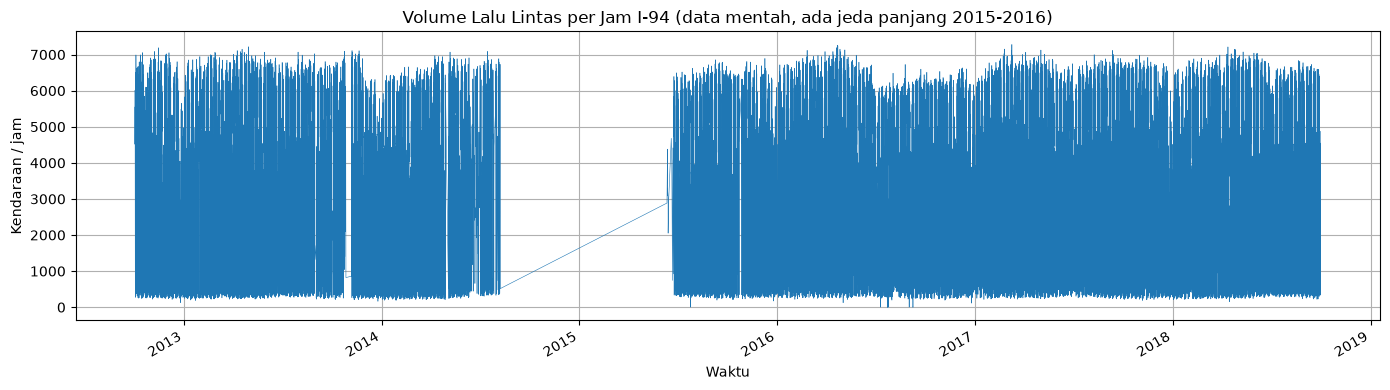

In [4]:
fig, ax = plt.subplots(figsize=(14, 4))
df["traffic_volume"].plot(ax=ax, lw=0.4)
ax.set_title("Volume Lalu Lintas per Jam I-94 (data mentah, ada jeda panjang 2015-2016)")
ax.set_xlabel("Waktu"); ax.set_ylabel("Kendaraan / jam"); ax.grid(True)
plt.tight_layout(); plt.savefig("figures/01_raw_series.png", dpi=150); plt.show()

In [5]:
# Pakai segmen setelah jeda panjang
START = "2016-04-01"
seg = df.loc[START:, ["traffic_volume"]]
full_idx = pd.date_range(seg.index.min(), seg.index.max(), freq="h")
print("Jam hilang pada segmen:", len(full_idx) - len(seg), f"({(len(full_idx)-len(seg))/len(full_idx):.2%})")

# Reindex ke frekuensi per jam, isi jam hilang dengan interpolasi waktu
series = seg.reindex(full_idx)
series.index.name = "date_time"
series["traffic_volume"] = series["traffic_volume"].interpolate(method="time", limit=12).bfill().ffill()
print("NaN tersisa:", series["traffic_volume"].isna().sum(), "| jumlah baris:", len(series))

Jam hilang pada segmen: 270 (1.23%)
NaN tersisa: 0 | jumlah baris: 21912


## 3. Eksplorasi Data (EDA): Tren, Musiman, Pola Lain

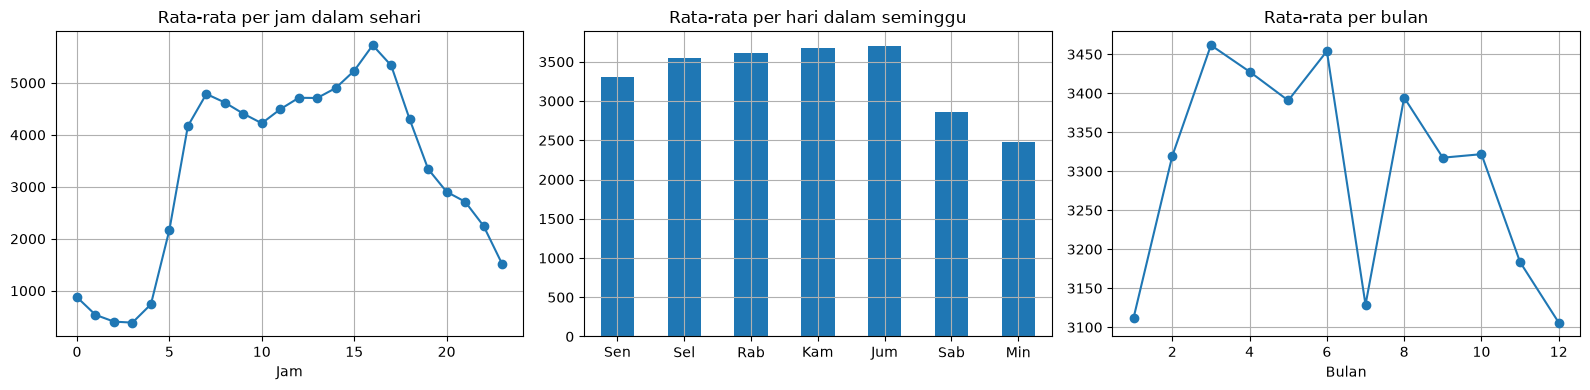

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
series.groupby(series.index.hour)["traffic_volume"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Rata-rata per jam dalam sehari"); axes[0].set_xlabel("Jam"); axes[0].grid(True)

hari = ["Sen","Sel","Rab","Kam","Jum","Sab","Min"]
dow = series.groupby(series.index.dayofweek)["traffic_volume"].mean(); dow.index = hari
dow.plot(kind="bar", ax=axes[1], rot=0); axes[1].set_title("Rata-rata per hari dalam seminggu"); axes[1].grid(True)

series.groupby(series.index.month)["traffic_volume"].mean().plot(ax=axes[2], marker="o")
axes[2].set_title("Rata-rata per bulan"); axes[2].set_xlabel("Bulan"); axes[2].grid(True)
plt.tight_layout(); plt.savefig("figures/02_seasonality.png", dpi=150); plt.show()

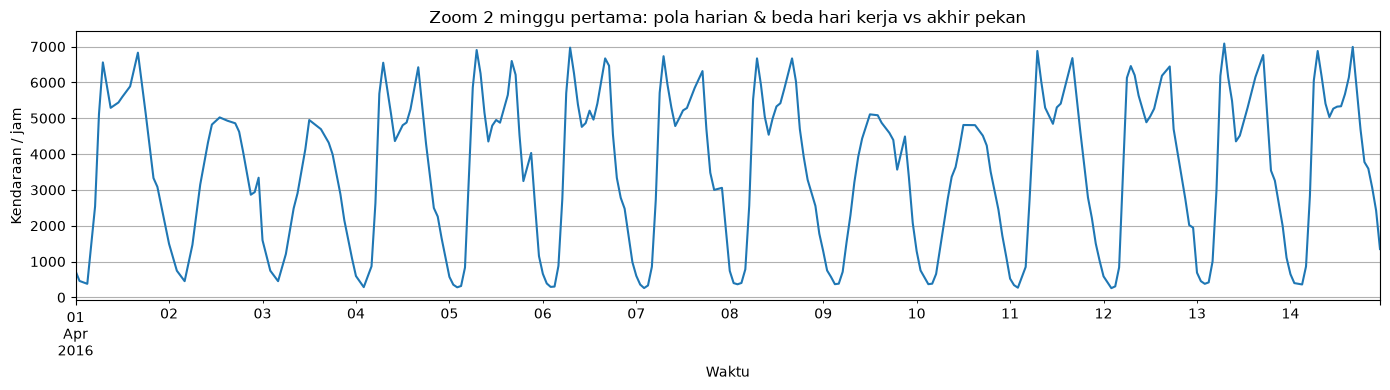

Autokorelasi lag 1 / 24 / 168 jam: [0.913, 0.867, 0.949]


In [7]:
fig, ax = plt.subplots(figsize=(14, 4))
series["traffic_volume"].iloc[:24*14].plot(ax=ax)
ax.set_title("Zoom 2 minggu pertama: pola harian & beda hari kerja vs akhir pekan")
ax.set_xlabel("Waktu"); ax.set_ylabel("Kendaraan / jam"); ax.grid(True)
plt.tight_layout(); plt.savefig("figures/03_zoom_2weeks.png", dpi=150); plt.show()

print("Autokorelasi lag 1 / 24 / 168 jam:",
      [round(series["traffic_volume"].autocorr(l), 3) for l in (1, 24, 168)])

## 4. Rekayasa Fitur
Fitur = volume lalu lintas + fitur kalender siklik (sin/cos untuk jam & hari). Fitur kalender **selalu diketahui di masa depan**, sehingga aman dipakai untuk peramalan multi-langkah di aplikasi web.

In [8]:
def calendar_features(idx):
    return np.column_stack([
        np.sin(2*np.pi*idx.hour/24), np.cos(2*np.pi*idx.hour/24),
        np.sin(2*np.pi*idx.dayofweek/7), np.cos(2*np.pi*idx.dayofweek/7),
    ])

FEATURES = ["traffic_volume", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
data = pd.DataFrame(
    np.column_stack([series["traffic_volume"].values, calendar_features(series.index)]),
    index=series.index, columns=FEATURES)
data.head()

,traffic_volume,hour_sin,hour_cos,dow_sin,dow_cos
date_time,,,,,
2016-04-01 00:00:00,731.0,0.000000,1.000000,-0.433884,-0.900969
2016-04-01 01:00:00,458.0,0.258819,0.965926,-0.433884,-0.900969
2016-04-01 02:00:00,418.0,0.500000,0.866025,-0.433884,-0.900969
2016-04-01 03:00:00,378.0,0.707107,0.707107,-0.433884,-0.900969
2016-04-01 04:00:00,1458.5,0.866025,0.500000,-0.433884,-0.900969


## 5. Split Kronologis & Scaling
Split **berdasarkan urutan waktu** (tanpa diacak). `MinMaxScaler` di-*fit* **hanya pada data latih** supaya tidak ada kebocoran data (*data leakage*) dari data uji.

In [9]:
n = len(data)
train_end = int(n * 0.8)
train_df, test_df = data.iloc[:train_end], data.iloc[train_end:]
print("Latih:", train_df.index.min(), "->", train_df.index.max(), len(train_df))
print("Uji  :", test_df.index.min(), "->", test_df.index.max(), len(test_df))

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_df.values)
scaled = scaler.transform(data.values)

Latih: 2016-04-01 00:00:00 -> 2018-04-01 08:00:00 17529
Uji  : 2018-04-01 09:00:00 -> 2018-09-30 23:00:00 4383


## 6. Windowing & Reshape ke Tensor 3D `(samples, timesteps, features)`

In [10]:
def make_sequences(arr, timesteps, target_col=0):
    X, y = [], []
    for i in range(timesteps, len(arr)):
        X.append(arr[i-timesteps:i, :])
        y.append(arr[i, target_col])
    return np.array(X), np.array(y)

# Data uji memakai 'timesteps' baris terakhir data latih sebagai konteks awal
X_train_all, y_train_all = make_sequences(scaled[:train_end], TIMESTEPS)
X_test, y_test = make_sequences(scaled[train_end - TIMESTEPS:], TIMESTEPS)

# Validasi = 10% terakhir dari data latih (kronologis)
val_start = int(len(X_train_all) * 0.9)
X_train, y_train = X_train_all[:val_start], y_train_all[:val_start]
X_val, y_val = X_train_all[val_start:], y_train_all[val_start:]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)  # (samples, timesteps, features)

X_train: (15732, 48, 5) | X_val: (1749, 48, 5) | X_test: (4383, 48, 5)


## 7. Membangun & Melatih Model LSTM

In [11]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
tf.random.set_seed(SEED)

model = Sequential([
    Input(shape=(TIMESTEPS, len(FEATURES))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1),
])
model.compile(optimizer="adam", loss="mean_squared_error")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 48, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=30, batch_size=64,
                    validation_data=(X_val, y_val), callbacks=[early], verbose=1)

Epoch 1/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - loss: 0.0300 - val_loss: 0.0110
Epoch 2/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 0.0112 - val_loss: 0.0054
Epoch 3/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 0.0079 - val_loss: 0.0066
Epoch 4/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - loss: 0.0069 - val_loss: 0.0052
Epoch 5/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 9s 36ms/step - loss: 0.0060 - val_loss: 0.0051
Epoch 6/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 16s 57ms/step - loss: 0.0057 - val_loss: 0.0047
Epoch 7/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - loss: 0.0054 - val_loss: 0.0043
Epoch 8/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 13s 55ms/step - loss: 0.0050 - val_loss: 0.0049
Epoch 9/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - loss: 0.0048 - val_loss: 0.0051
Epoch 10/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - loss: 0.0044 - val_loss: 0.0045
Epoch 11/30
246/246 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - loss: 0.0042 - val_loss: 0.0040
Epoch 12/30
246/246 ━━━━━━━━━━━━━

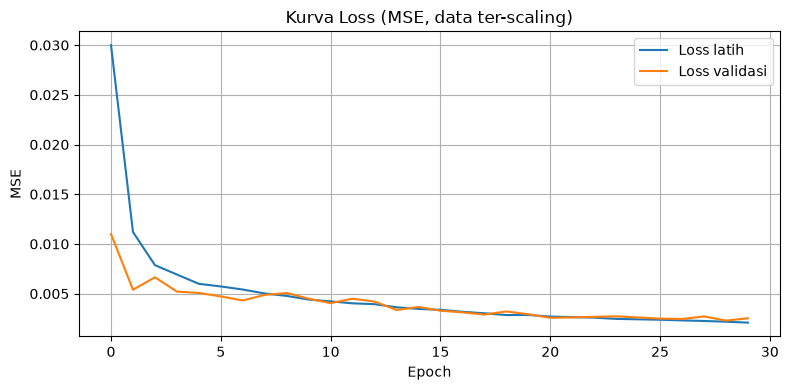

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Loss latih")
plt.plot(history.history["val_loss"], label="Loss validasi")
plt.title("Kurva Loss (MSE, data ter-scaling)"); plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("figures/04_loss_curve.png", dpi=150); plt.show()

## 8. Evaluasi pada Data Uji
Prediksi & nilai aktual dikembalikan ke skala asli (*inverse transform*). Model dibandingkan dengan dua *baseline*: **persistence** (nilai = jam sebelumnya) dan **seasonal naive** (nilai = jam yang sama minggu lalu).

In [14]:
v_min, v_rng = scaler.data_min_[0], scaler.data_range_[0]
inv = lambda a: np.clip(np.asarray(a).reshape(-1) * v_rng + v_min, 0, None)

pred = inv(model.predict(X_test, verbose=0))
actual = inv(y_test)
test_index = data.index[train_end:]

def report(name, y, p):
    rmse = float(np.sqrt(mean_squared_error(y, p)))
    mae = float(mean_absolute_error(y, p))
    r2 = float(r2_score(y, p))
    print(f"{name:<16} RMSE={rmse:8.2f}  MAE={mae:8.2f}  R2={r2:6.3f}")
    return {"rmse": round(rmse, 2), "mae": round(mae, 2), "r2": round(r2, 4)}

full_vol = data["traffic_volume"].values
persist = full_vol[train_end-1:-1]          # jam sebelumnya
seasonal = full_vol[train_end-168:-168]     # jam yang sama minggu lalu

metrics = {
    "LSTM": report("LSTM", actual, pred),
    "Persistence": report("Persistence", actual, persist),
    "Seasonal naive": report("Seasonal naive", actual, seasonal),
}

LSTM             RMSE=  301.02  MAE=  226.02  R2= 0.977
Persistence      RMSE=  813.49  MAE=  585.56  R2= 0.831
Seasonal naive   RMSE=  613.50  MAE=  300.62  R2= 0.904


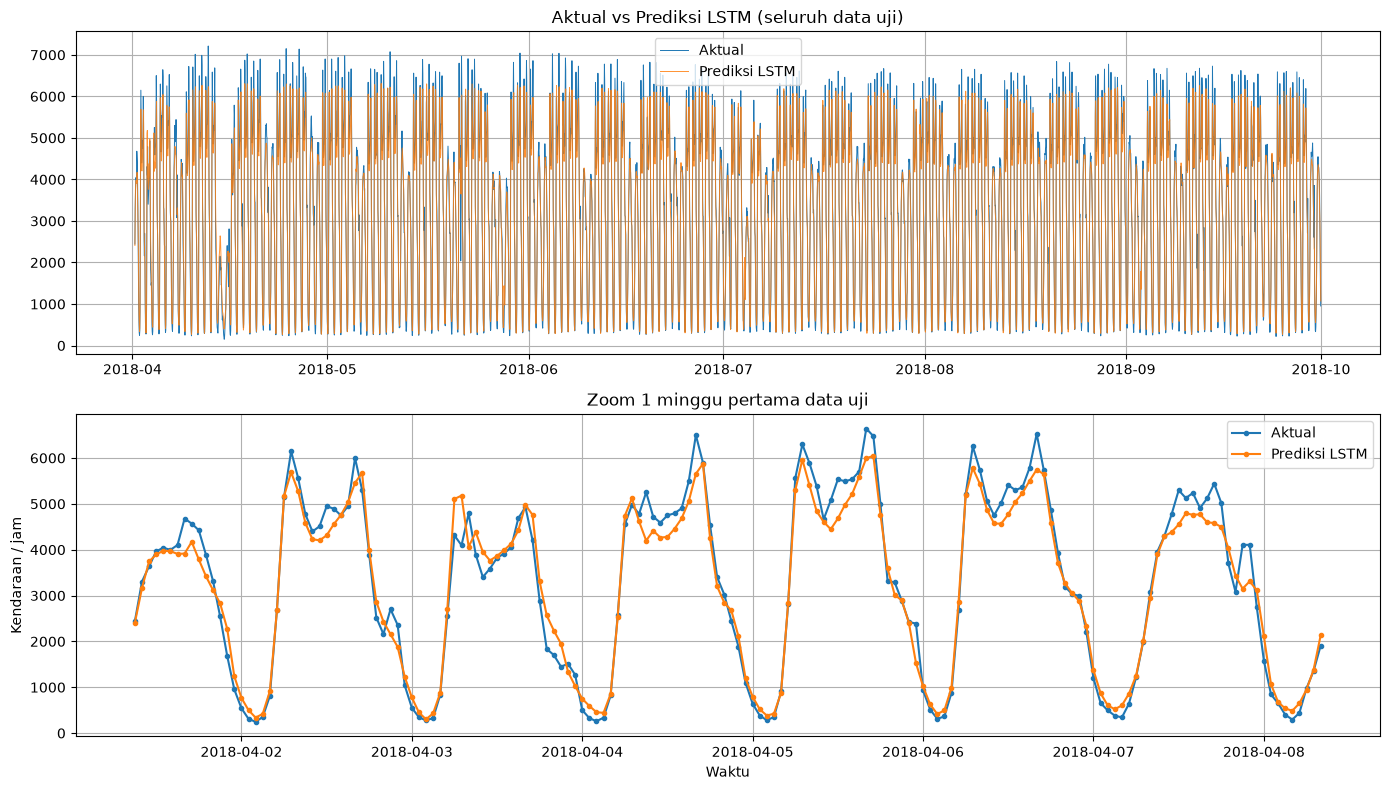

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(test_index, actual, label="Aktual", lw=0.7)
axes[0].plot(test_index, pred, label="Prediksi LSTM", lw=0.7, alpha=0.85)
axes[0].set_title("Aktual vs Prediksi LSTM (seluruh data uji)"); axes[0].legend(); axes[0].grid(True)

k = 24*7
axes[1].plot(test_index[:k], actual[:k], label="Aktual", marker=".")
axes[1].plot(test_index[:k], pred[:k], label="Prediksi LSTM", marker=".")
axes[1].set_title("Zoom 1 minggu pertama data uji"); axes[1].set_xlabel("Waktu"); axes[1].set_ylabel("Kendaraan / jam")
axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.savefig("figures/05_actual_vs_pred.png", dpi=150); plt.show()

## 9. Menyimpan Model, Scaler, dan Data Pendukung Aplikasi Flask

In [16]:
model.save("model/lstm_traffic.h5")
joblib.dump(scaler, "model/scaler.joblib")

# Data pendukung untuk aplikasi web
series[["traffic_volume"]].iloc[-24*30:].to_csv("model/recent.csv")                 # 30 hari terakhir
pd.DataFrame({"date_time": test_index, "actual": actual, "predicted": pred}).to_csv("model/test_results.csv", index=False)
with open("model/metrics.json", "w") as f:
    json.dump({"timesteps": TIMESTEPS, "features": FEATURES, "metrics": metrics,
               "data_start": str(series.index.min()), "data_end": str(series.index.max())}, f, indent=2)
print("Tersimpan di folder model/:", os.listdir("model"))

Tersimpan di folder model/: ['lstm_traffic.h5', 'metrics.json', 'recent.csv', 'scaler.joblib', 'test_results.csv']


## 10. Kesimpulan (isi setelah menjalankan notebook)
- Ringkas RMSE/MAE/R2 LSTM vs baseline.
- Apakah LSTM menangkap pola harian (jam sibuk pagi/sore) dan beda hari kerja vs akhir pekan?
- Keterbatasan & ide perbaikan (fitur cuaca, hari libur, timesteps lain, GRU, dsb).